# Track 1 — Q1.1 and Q1.2: Calibration–Refinement Training Dynamics

**Experiment Plan:** Track 1, Figure 1-B.

**Experiment questions answered in this notebook:**

> **Q1.1.** Does the calibration–refinement decomposition of proper losses hold in end-to-end training, and do calibration and refinement move in opposite directions during training (as suggested theoretically by Berta et al.)?
>
> **Q1.2.** How does the calibration–refinement trade-off evolve over training epochs? Is there a phase transition (e.g. early training improves refinement, late training worsens calibration) that the calibration penalty can prevent?

This notebook implements the differentiable soft-binned calibration penalty ($\widehat{C}_e^{\text{soft}}$), the evaluation-time hard-binned calibrtion-refinement decomposition, the composite training objective $\mathcal{L}_\lambda$ and a full-batch gradient-descent training loop. It first inspects **one representative configuration** (CE base loss, $\lambda=0.5$), then produces the **full Figure 1-B grid** across the primary capacities, four values of $\lambda$, and both base losses (CE and Brier).

The figures aggregate **five independent seeds**. Lines show the mean trajectory and shaded regions show one sample standard deviation across seeds, making between-seed variability visible.

## 0. Setup

This cell recreates `track1_core.py` from Notebook 1 (Setup), so this notebook can run
standalone in a fresh Colab runtime without needing to re-run or upload anything.


In [2]:
%%writefile track1_core.py
'''Track 1 core utilities: data-generating process + Legendre basis model.
Copied from Notebook 1 (Setup) so this notebook is self-contained.'''
import numpy as np
import pandas as pd
from scipy.special import eval_legendre
from matplotlib.ticker import MultipleLocator, MaxNLocator

TEST_SEED = 999
N_TEST = 50_000
CAPACITY_GRID = [5, 10, 100, 120, 200, 300, 1000]
PRIMARY_CAPACITIES = [10, 100, 1000]
INIT_SCALE = np.sqrt(0.01)

def true_eta(x):
    x = np.asarray(x, dtype=np.float64)
    return 0.1 + 0.8 / (1.0 + np.exp(-4.0 * np.sin(np.pi * x)))

def generate_data(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1.0, 1.0, size=n)
    Y = rng.binomial(1, true_eta(X)).astype(np.float64)
    return X, Y

def get_fixed_test_set():
    return generate_data(n=N_TEST, seed=TEST_SEED)

def legendre_design_matrix(x, m):
    '''
    Three-term recurrence, O(n*m). Do NOT replace with a per-degree eval_legendre loop --
    that is O(n*m^2) and takes ~113s at m=1000 on a 50,000-point test set vs. ~2.4s here.
    '''
    x = np.asarray(x, dtype=np.float64)
    # return np.stack([eval_legendre(k, x) for k in range(m + 1)], axis=1)
    n = x.shape[0]
    Phi = np.empty((n, m + 1), dtype=np.float64)
    Phi[:, 0] = 1.0
    if m >= 1:
        Phi[:, 1] = x
    for k in range(2, m + 1):
        Phi[:, k] = ((2 * k - 1) * x * Phi[:, k - 1] - (k - 1) * Phi[:, k - 2]) / k
    return Phi

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def init_theta(m, seed):
    rng = np.random.default_rng(seed)
    return rng.normal(loc=0.0, scale=INIT_SCALE, size=m + 1)

def model_predict(theta, Phi):
    return sigmoid(Phi @ theta)

Writing track1_core.py


In [3]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import track1_core as t1

torch.set_default_dtype(torch.float64)  # match numpy float64 used in Notebook 1

PALETTE_CAPACITY = {10: "#264653", 100: "#e9c46a", 1000: "#e76f51"}
plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    # "font.family": "serif",
    # "font.serif": ["Computer Modern Roman", "CMU Serif"],
    # "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    # "savefig.bbox": "tight",
    # "savefig.pad_inches": 0.05,
    "savefig.format": "pdf"
})

np.set_printoptions(precision=4, suppress=True)

DATA_SEED = 1     # fixed data seed for all mechanism runs in this notebook
INIT_SEED = 42    # fixed init seed, deliberately different from DATA_SEED (per plan's note)
EPOCHS = 1200
LOG_EVERY = 5     # log every 5 epochs -> 241 points per curve, enough resolution, faster to run

## 1. Soft-binned ECE penalty (training-time, differentiable)

$$
\widehat{C}_e^{\text{soft}}(\theta) = \sum_{b=1}^{B} \Big(\tfrac{1}{n}\textstyle\sum_i w_{ib}\Big)
\big(\bar y_b - \bar p_b\big)^2, \qquad
w_{ib} = \mathrm{softmax}_b\!\Big(-\tfrac{(p_i - c_b)^2}{2h^2}\Big), \qquad c_b = \tfrac{b - 1/2}{B}
$$

**Straight-through gradient:** the plan requires the gradient to be computed "via chain rule with a straight-through approximation on the bin weights (treating $w_{ib}$ as constants when differentiating through $\bar p_b$)". In PyTorch this means calling `.detach()` on the softmax bin weights before using them to form $\bar p_b$, $\bar y_b$, and the bin mass — gradient still flows into the penalty through the $p_i$ factor inside $\bar p_b$, just not through the bin *assignment* itself.

In [4]:
def soft_ece_penalty(p, y, B=15, h=0.08):
    '''
    p: torch tensor (n,) predictions (requires_grad=True upstream)
    y: torch tensor (n,) labels in {0,1}
    Returns scalar C_e^soft(theta). Straight-through: bin weights are detached.
    '''
    n = p.shape[0]
    centers = (torch.arange(1, B + 1, dtype=p.dtype) - 0.5) / B
    d2 = (p.unsqueeze(1) - centers.unsqueeze(0)) ** 2
    logits = -d2 / (2 * h ** 2)
    w = torch.softmax(logits, dim=1)
    w_sg = w.detach()  # straight-through approximation, per plan §1.5

    bin_mass = w_sg.sum(dim=0)
    eps = 1e-12
    pbar = (w_sg * p.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    ybar = (w_sg * y.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    return ((bin_mass / n) * (ybar - pbar) ** 2).sum()

### Sanity checks

1. The penalty is finite and differentiable (gradient w.r.t. predictions exists and is nonzero).
2. Predictions that are *calibrated by construction* (labels drawn at the predicted rate) get a
   noticeably lower penalty than predictions that are *systematically miscalibrated* (labels
   drawn at a different rate than reported).


In [5]:
torch.manual_seed(0)
p_test = torch.rand(50, requires_grad=True)
y_test = torch.randint(0, 2, (50,)).double()
pen = soft_ece_penalty(p_test, y_test)
pen.backward()
print(f"penalty value: {pen.item():.6f}")
print(f"grad finite: {torch.isfinite(p_test.grad).all().item()}, "
      f"grad nonzero: {(p_test.grad.abs() > 0).any().item()}")
assert torch.isfinite(pen) and torch.isfinite(p_test.grad).all()

torch.manual_seed(1)
n_cal = 5000
p_cal = torch.rand(n_cal)
y_cal = torch.bernoulli(p_cal)                                    # calibrated by construction
pen_cal = soft_ece_penalty(p_cal, y_cal).item()

p_mis = torch.rand(n_cal)
y_mis = torch.bernoulli(torch.clamp(p_mis + 0.3, 0, 1))           # systematically miscalibrated
pen_mis = soft_ece_penalty(p_mis, y_mis).item()

print(f"\ncalibrated-by-construction penalty:   {pen_cal:.5f}")
print(f"systematically-miscalibrated penalty: {pen_mis:.5f}")
assert pen_cal < pen_mis
print("OK: soft-ECE penalty is lower for calibrated predictions, as expected.")

penalty value: 0.068435
grad finite: True, grad nonzero: True

calibrated-by-construction penalty:   0.00005
systematically-miscalibrated penalty: 0.06984
OK: soft-ECE penalty is lower for calibrated predictions, as expected.


## 2. Hard-binned calibration–refinement decomposition (evaluation only)

Used only for **logging/plotting**, never inside the training loop (10 equal-width bins).

$$
\widehat{\mathcal C}_{\text{Brier}} = \sum_b \frac{n_b}{N}(\bar p_b - \bar y_b)^2, \qquad
\widehat{\mathcal R}_{\text{Brier}} := \widehat{\mathcal E}_{\text{Brier}} - \widehat{\mathcal C}_{\text{Brier}}
$$

$$
\widehat{\mathcal C}_{\text{CE}} = \sum_b \frac{n_b}{N}\, \mathrm{KL}(\bar y_b \,\|\, \bar p_b), \qquad
\widehat{\mathcal R}_{\text{CE}} := \widehat{\mathcal E}_{\text{CE}} - \widehat{\mathcal C}_{\text{CE}}
$$

In [6]:
def hard_binned_decomposition(p, y, B=10, eps=1e-12):
    '''p, y: numpy arrays (n,). Returns dict of total/cal/ref for CE and Brier, B equal-width bins.'''
    p = np.clip(np.asarray(p, dtype=np.float64), eps, 1 - eps)
    y = np.asarray(y, dtype=np.float64)
    n = len(p)
    edges = np.linspace(0.0, 1.0, B + 1)
    bin_idx = np.clip(np.digitize(p, edges[1:-1], right=False), 0, B - 1)

    ce_total = np.mean(-y * np.log(p) - (1 - y) * np.log(1 - p))
    brier_total = np.mean((p - y) ** 2)

    brier_cal, ce_cal = 0.0, 0.0
    for b in range(B):
        mask = bin_idx == b
        n_b = mask.sum()
        if n_b == 0:
            continue
        pbar_b, ybar_b = p[mask].mean(), y[mask].mean()
        weight = n_b / n
        brier_cal += weight * (pbar_b - ybar_b) ** 2
        pbar_c = min(max(pbar_b, eps), 1 - eps)
        ybar_c = min(max(ybar_b, eps), 1 - eps)
        ce_cal += weight * (ybar_c * np.log(ybar_c / pbar_c)
                             + (1 - ybar_c) * np.log((1 - ybar_c) / (1 - pbar_c)))

    return {
        "ce_total": ce_total, "ce_cal": ce_cal, "ce_ref": ce_total - ce_cal,
        "brier_total": brier_total, "brier_cal": brier_cal, "brier_ref": brier_total - brier_cal,
    }

### Sanity checks

1. When predictions equal the true generating rate (calibrated by construction, large $n$), both calibration terms should be close to zero.
2. When predictions are pushed to be systematically overconfident relative to the true rate, both calibration terms should increase.
3. Total = Calibration + Refinement should hold **exactly** (refinement is a residual by definition, not an independently estimated quantity).


In [7]:
rng = np.random.default_rng(0)
n_big = 200_000

p_perfect = rng.uniform(0.05, 0.95, n_big)
y_perfect = rng.binomial(1, p_perfect)
dec_perfect = hard_binned_decomposition(p_perfect, y_perfect, B=10)

p_over = rng.uniform(0.05, 0.95, n_big)
y_over = rng.binomial(1, p_over)
p_over_reported = np.clip(0.5 + 1.8 * (p_over - 0.5), 0.01, 0.99)  # sharper than true rate
dec_over = hard_binned_decomposition(p_over_reported, y_over, B=10)

print("calibrated-by-construction:", {k: round(v, 5) for k, v in dec_perfect.items()})
print("overconfident:              ", {k: round(v, 5) for k, v in dec_over.items()})

assert dec_perfect["brier_cal"] < 0.002 and dec_perfect["ce_cal"] < 0.01
assert dec_over["brier_cal"] > dec_perfect["brier_cal"]
assert dec_over["ce_cal"] > dec_perfect["ce_cal"]
assert abs(dec_perfect["brier_total"] - (dec_perfect["brier_cal"] + dec_perfect["brier_ref"])) < 1e-10
assert abs(dec_over["ce_total"] - (dec_over["ce_cal"] + dec_over["ce_ref"])) < 1e-10
print("\nOK: decomposition responds correctly to (mis)calibration, and total = cal + ref exactly.")

calibrated-by-construction: {'ce_total': np.float64(0.54597), 'ce_cal': np.float64(4e-05), 'ce_ref': np.float64(0.54593), 'brier_total': np.float64(0.18369), 'brier_cal': np.float64(1e-05), 'brier_ref': np.float64(0.18368)}
overconfident:               {'ce_total': np.float64(0.68964), 'ce_cal': np.float64(0.12403), 'ce_ref': np.float64(0.56561), 'brier_total': np.float64(0.20069), 'brier_cal': np.float64(0.01598), 'brier_ref': np.float64(0.18471)}

OK: decomposition responds correctly to (mis)calibration, and total = cal + ref exactly.


## 3. Composite training objective and training loop

$$
\mathcal{L}_\lambda(\theta) = (1-\lambda)\,\widehat{\mathcal C}_e^{\text{soft}}(\theta) + \lambda\,\widehat{\mathcal E}(\theta),
\qquad \lambda \in (0, 1]
$$

with $\widehat{\mathcal E}$ the base loss (CE or Brier). Optimisation is full-batch gradient descent, learning rate $\eta = 0.5$, 1200 epochs, no early stopping.


In [8]:
def base_loss_fn(p, y, kind):
    eps = 1e-12
    if kind == "ce":
        p_c = p.clamp(eps, 1 - eps)
        return -(y * torch.log(p_c) + (1 - y) * torch.log(1 - p_c)).mean()
    elif kind == "brier":
        return ((p - y) ** 2).mean()
    else:
        raise ValueError(kind)


def train_track1_model(m, data_seed, init_seed, lam, base_loss="ce",
                        lr=0.5, epochs=EPOCHS, log_every=LOG_EVERY,
                        soft_ece_B=15, soft_ece_h=0.08, eval_B=10):
    '''
    Full-batch GD on L_lambda = (1-lambda) * C_soft + lambda * E_hat.
    lambda=1.0 recovers the pure baseline (CE or Brier).
    Returns dict of per-epoch logs: epoch, train[...], test[...] (each a hard_binned_decomposition dict).
    '''
    X_tr, Y_tr = t1.generate_data(n=100, seed=data_seed)
    X_te, Y_te = t1.get_fixed_test_set()

    Phi_tr = torch.tensor(t1.legendre_design_matrix(X_tr, m))
    Phi_te = torch.tensor(t1.legendre_design_matrix(X_te, m))
    y_tr_t = torch.tensor(Y_tr)

    theta = torch.tensor(t1.init_theta(m, init_seed), requires_grad=True)

    logs = {"epoch": [], "train": [], "test": []}
    for epoch in range(epochs + 1):
        p_tr = torch.sigmoid(Phi_tr @ theta)
        e_hat = base_loss_fn(p_tr, y_tr_t, base_loss)
        c_soft = soft_ece_penalty(p_tr, y_tr_t, B=soft_ece_B, h=soft_ece_h)
        loss = (1 - lam) * c_soft + lam * e_hat

        if theta.grad is not None:
            theta.grad.zero_()
        loss.backward()
        with torch.no_grad():
            theta -= lr * theta.grad

        if epoch % log_every == 0:
            with torch.no_grad():
                p_tr_np = torch.sigmoid(Phi_tr @ theta).numpy()
                p_te_np = torch.sigmoid(Phi_te @ theta).numpy()
            logs["epoch"].append(epoch)
            logs["train"].append(hard_binned_decomposition(p_tr_np, Y_tr, B=eval_B))
            logs["test"].append(hard_binned_decomposition(p_te_np, Y_te, B=eval_B))

    return logs

### Timing check

One run at the largest primary capacity ($m=1000$, 1200 epochs) — this determines whether the
full sweep below (3 capacities × 4 $\lambda$ × 2 base losses = 24 runs) is feasible in a single Colab session. This is exactly the case the recurrence-based design
matrix fix from Notebook 1 was needed for: with the old per-degree `eval_legendre` construction
this run would rebuild a (50000, 1001) matrix from scratch on every one of the 241 logging steps.


In [9]:
# import time
# t0 = time.time()
# _ = train_track1_model(m=1000, data_seed=DATA_SEED, init_seed=INIT_SEED, lam=0.5, base_loss="ce")
# t1_ = time.time()
# print(f"m=1000, 1200 epochs: {t1_ - t0:.1f}s")
# print(f"capacity-sweep estimate (m=10+100+1000): ~{t1_ - t0 + 8:.0f}s "
#       f"-> full 8-config grid estimate: ~{(t1_ - t0 + 8) * 8:.0f}s")

## 4. Figure 1-B — one representative configuration (CE, $\lambda=0.5$)

First, we are building and inspecting a single configuration first, before generating the full grid, so any issues are easy to spot. Each configuration is run with five independent data/init seed pairs; the plotted line is the across-seed mean and the same-colour band is mean $\pm$ one sample standard deviation.

Using the primary capacities $\{10, 100, 1000\}$: under-parameterised, exactly at the interpolation threshold ($m=n_{\text{train}}=100$), and strongly overparameterised. Per Notebook Track1_00's Figure 1-A, both $m=100$ and $m=1000$ are essentially bias-free representations of $\eta(x)$ (approximation error $\sim 10^{-12}$), so any calibration differences between them reflect the *estimator*, not the function class.

  seed 1/5: data_seed=1, init_seed=42
  seed 2/5: data_seed=101, init_seed=142
  seed 3/5: data_seed=201, init_seed=242
  seed 4/5: data_seed=301, init_seed=342
  seed 5/5: data_seed=401, init_seed=442


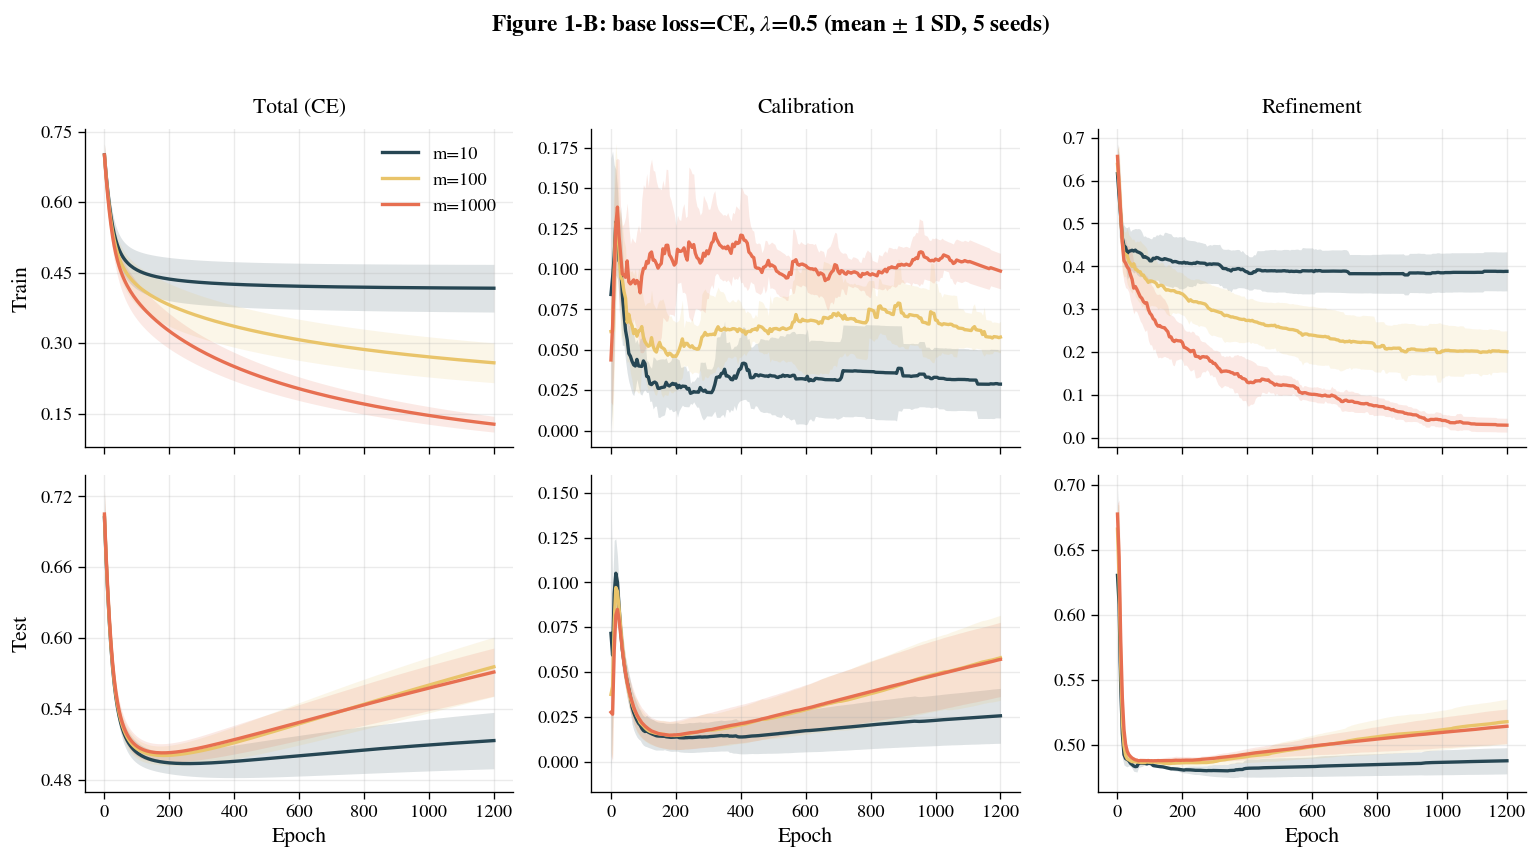

In [16]:
from matplotlib.ticker import MultipleLocator, MaxNLocator

N_SEEDS = 5
SEED_OFFSETS = [0, 1, 2, 3, 4]

def run_capacity_sweep(lam, base_loss, capacities=t1.PRIMARY_CAPACITIES,
                        data_seed=DATA_SEED, init_seed=INIT_SEED):
    """Run one seed across capacities (used as a small helper)."""
    return {m: train_track1_model(m=m, data_seed=data_seed, init_seed=init_seed,
                                   lam=lam, base_loss=base_loss)
            for m in capacities}

def run_multiseed_capacity_sweep(lam, base_loss, capacities=t1.PRIMARY_CAPACITIES):
    """Return results[m] as a list of five independent per-seed training logs."""
    results = {m: [] for m in capacities}
    for seed_offset in SEED_OFFSETS:
        data_seed = DATA_SEED + 100 * seed_offset
        init_seed = INIT_SEED + 100 * seed_offset
        one_seed = run_capacity_sweep(
            lam=lam, base_loss=base_loss, capacities=capacities,
            data_seed=data_seed, init_seed=init_seed
        )
        for m in capacities:
            results[m].append(one_seed[m])
        print(f"  seed {seed_offset + 1}/{N_SEEDS}: data_seed={data_seed}, init_seed={init_seed}")
    return results

def mean_std_trajectory(seed_logs, split, key):
    """Across-seed mean and sample SD at each logged epoch."""
    epochs_arr = np.asarray(seed_logs[0]["epoch"])
    values = np.asarray([[d[key] for d in run[split]] for run in seed_logs], dtype=float)
    return epochs_arr, values.mean(axis=0), values.std(axis=0, ddof=1)

def plot_figure_1b(results, lam, base_loss, capacities=t1.PRIMARY_CAPACITIES):
    """2x3 grid: rows=train/test, cols=total/calibration/refinement; mean and +/-1 SD across seeds."""
    col_keys = [f"{base_loss}_total", f"{base_loss}_cal", f"{base_loss}_ref"]
    col_titles = [f"Total ({base_loss.upper()})", "Calibration", "Refinement"]

    fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
    for row, split in enumerate(["train", "test"]):
        for col, (key, title) in enumerate(zip(col_keys, col_titles)):
            ax = axes[row, col]
            for m in capacities:
                epochs_arr, mean_vals, std_vals = mean_std_trajectory(results[m], split, key)
                color = PALETTE_CAPACITY[m]
                ax.plot(epochs_arr, mean_vals, color=color, lw=2.0, label=f"m={m}")
                ax.fill_between(epochs_arr, mean_vals - std_vals, mean_vals + std_vals,
                                color=color, alpha=0.15, linewidth=0)
            if row == 1:
                ax.set_xlabel("Epoch", labelpad=4)
                ax.xaxis.set_major_locator(MultipleLocator(200))
            if col == 0:
                ax.set_ylabel(split.capitalize(), labelpad=5)
                ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            if row == 0:
                ax.set_title(title, pad=10)
            if row == 0 and col == 0:
                ax.legend(frameon=False, loc="best")
            ax.tick_params(axis="both", which="major", length=4, width=0.8)
    fig.suptitle(f"Figure 1-B: base loss={base_loss.upper()}, $\\lambda$={lam} (mean $\\pm$ 1 SD, {N_SEEDS} seeds)", y=1.02)
    fig.tight_layout()
    fig.savefig(f"Figure_1B_lambda{lam}_{base_loss}.pdf", format="pdf", bbox_inches="tight")
    return fig

res_demo = run_multiseed_capacity_sweep(lam=0.5, base_loss="ce")
fig_demo = plot_figure_1b(res_demo, lam=0.5, base_loss="ce")
plt.show()

In [17]:
def format_mean_sd(values, digits=4):
    """Format a sequence of seed-level values as mean ± sample SD."""
    values = np.asarray(values, dtype=float)
    return f"{values.mean():.{digits}f} ± {values.std(ddof=1):.{digits}f}"

print("Test-set CE decomposition, epoch 0 -> epoch 1200 (mean ± sample SD across 5 seeds):\n")
for m in t1.PRIMARY_CAPACITIES:
    seed_logs = res_demo[m]
    d0_total = [run["test"][0]["ce_total"] for run in seed_logs]
    dend_total = [run["test"][-1]["ce_total"] for run in seed_logs]
    d0_cal = [run["test"][0]["ce_cal"] for run in seed_logs]
    dend_cal = [run["test"][-1]["ce_cal"] for run in seed_logs]
    d0_ref = [run["test"][0]["ce_ref"] for run in seed_logs]
    dend_ref = [run["test"][-1]["ce_ref"] for run in seed_logs]
    print(f"m={m:>3}:  total {format_mean_sd(d0_total, 3)} -> {format_mean_sd(dend_total, 3)}   |   "
          f"cal {format_mean_sd(d0_cal)} -> {format_mean_sd(dend_cal)}   |   "
          f"ref {format_mean_sd(d0_ref)} -> {format_mean_sd(dend_ref)}")

Test-set CE decomposition, epoch 0 -> epoch 1200 (mean ± sample SD across 5 seeds):

m= 10:  total 0.702 ± 0.021 -> 0.513 ± 0.024   |   cal 0.0715 ± 0.0805 -> 0.0255 ± 0.0153   |   ref 0.6303 ± 0.0663 -> 0.4876 ± 0.0101
m=100:  total 0.703 ± 0.021 -> 0.576 ± 0.025   |   cal 0.0374 ± 0.0317 -> 0.0580 ± 0.0237   |   ref 0.6659 ± 0.0190 -> 0.5177 ± 0.0172
m=1000:  total 0.705 ± 0.021 -> 0.571 ± 0.020   |   cal 0.0275 ± 0.0243 -> 0.0570 ± 0.0207   |   ref 0.6775 ± 0.0083 -> 0.5141 ± 0.0134


### Interpretation of the representative run

For this single CE run at $\lambda=0.5$, refinement decreases throughout training. At $m=100$ and $m=1000$, test calibration error increases while refinement continues to improve, whereas the change is smaller at $m=10$. The train--test calibration gap also develops over training rather than appearing entirely at initialisation.

These trajectories are consistent with a calibration--refinement trade-off, but this one configuration is illustrative only. The full grid below checks whether the pattern depends on the base loss or on $\lambda$.


## 5. Full Figure 1-B grid — all primary $\lambda$ values, both loss families

Now we run the full grid separately for each $\lambda$ and for both CE and Brier training families.
$\lambda$ sweep: $\{0.0, 0.1, 0.5, 1.0\}$ (convex-combination form), capacities restricted to the primary set $\{10, 100, 1000\}$ to keep runtime
reasonable (8 configurations × 3 capacities = 24 training runs total).

**Note on $\lambda=0$:** At $\lambda=0$ the objective is pure soft-ECE with no accuracy term at all — worth watching for degenerate solutions (e.g. collapsing to a constant prediction), which is itself informative for the later Q1.11 question about whether the penalty pushes toward the true $\eta(x)$ or merely toward a flat, "trivially calibrated" predictor.


In [18]:
import time
LAMBDA_GRID = [0.0, 0.1, 0.5, 1.0]
BASE_LOSSES = ["ce", "brier"]

all_results = {}  # all_results[(lam, base_loss)][m] = logs
t_start = time.time()
for base_loss in BASE_LOSSES:
    for lam in LAMBDA_GRID:
        print(f"Starting: base_loss={base_loss}, lambda={lam}")
        all_results[(lam, base_loss)] = run_multiseed_capacity_sweep(
            lam=lam, base_loss=base_loss
        )
        print(f"done: base_loss={base_loss}, lambda={lam}  "
              f"(elapsed {time.time() - t_start:.0f}s)")
print(f"\nTotal grid runtime: {time.time() - t_start:.0f}s")

Starting: base_loss=ce, lambda=0.0
  seed 1/5: data_seed=1, init_seed=42
  seed 2/5: data_seed=101, init_seed=142
  seed 3/5: data_seed=201, init_seed=242
  seed 4/5: data_seed=301, init_seed=342
  seed 5/5: data_seed=401, init_seed=442
done: base_loss=ce, lambda=0.0  (elapsed 101s)
Starting: base_loss=ce, lambda=0.1
  seed 1/5: data_seed=1, init_seed=42
  seed 2/5: data_seed=101, init_seed=142
  seed 3/5: data_seed=201, init_seed=242
  seed 4/5: data_seed=301, init_seed=342
  seed 5/5: data_seed=401, init_seed=442
done: base_loss=ce, lambda=0.1  (elapsed 209s)
Starting: base_loss=ce, lambda=0.5
  seed 1/5: data_seed=1, init_seed=42
  seed 2/5: data_seed=101, init_seed=142
  seed 3/5: data_seed=201, init_seed=242
  seed 4/5: data_seed=301, init_seed=342
  seed 5/5: data_seed=401, init_seed=442
done: base_loss=ce, lambda=0.5  (elapsed 317s)
Starting: base_loss=ce, lambda=1.0
  seed 1/5: data_seed=1, init_seed=42
  seed 2/5: data_seed=101, init_seed=142
  seed 3/5: data_seed=201, init_se

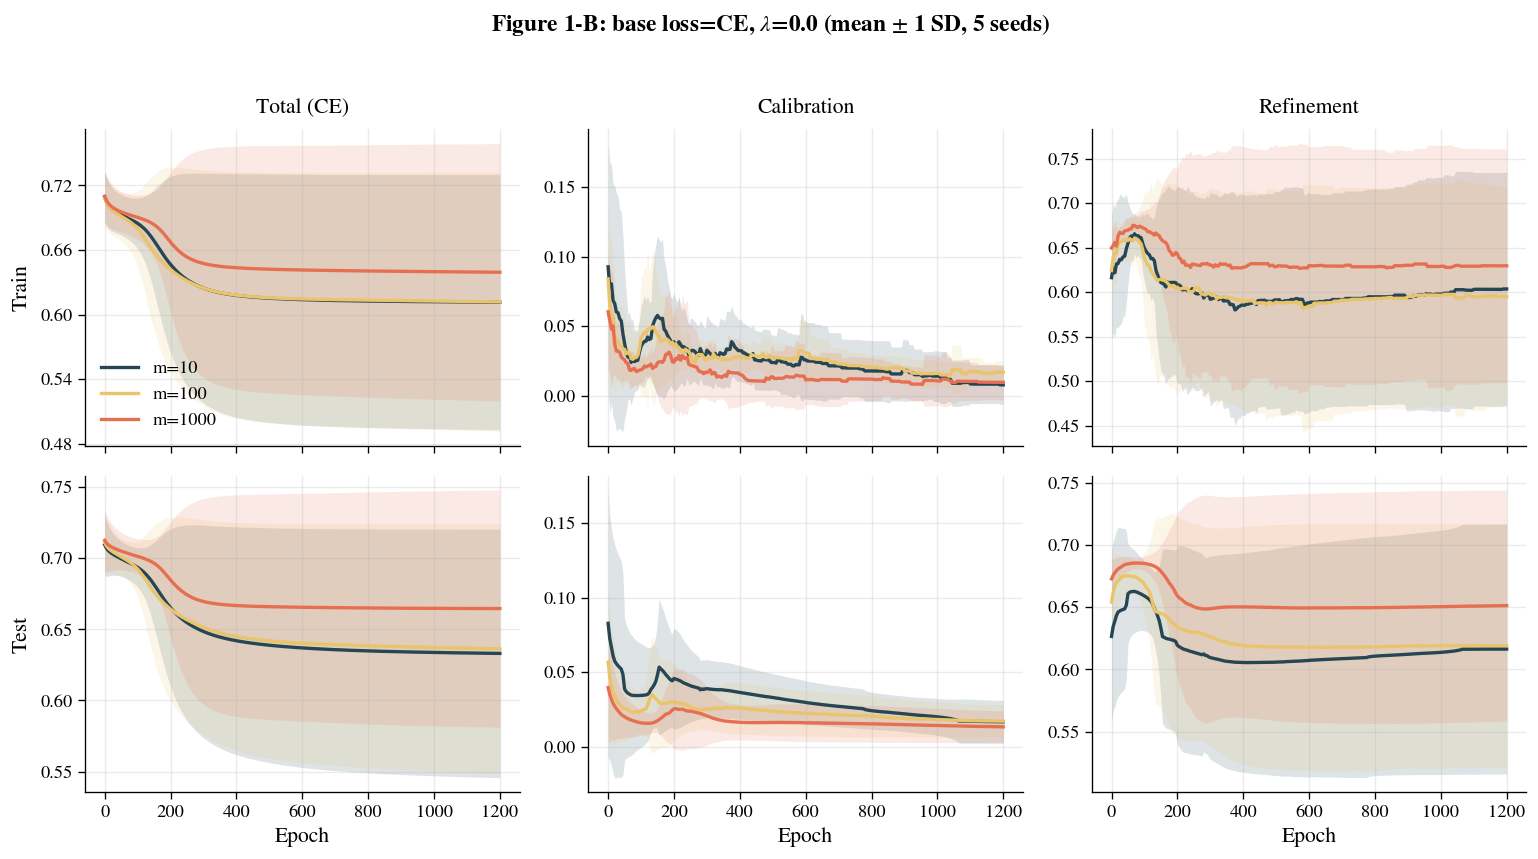

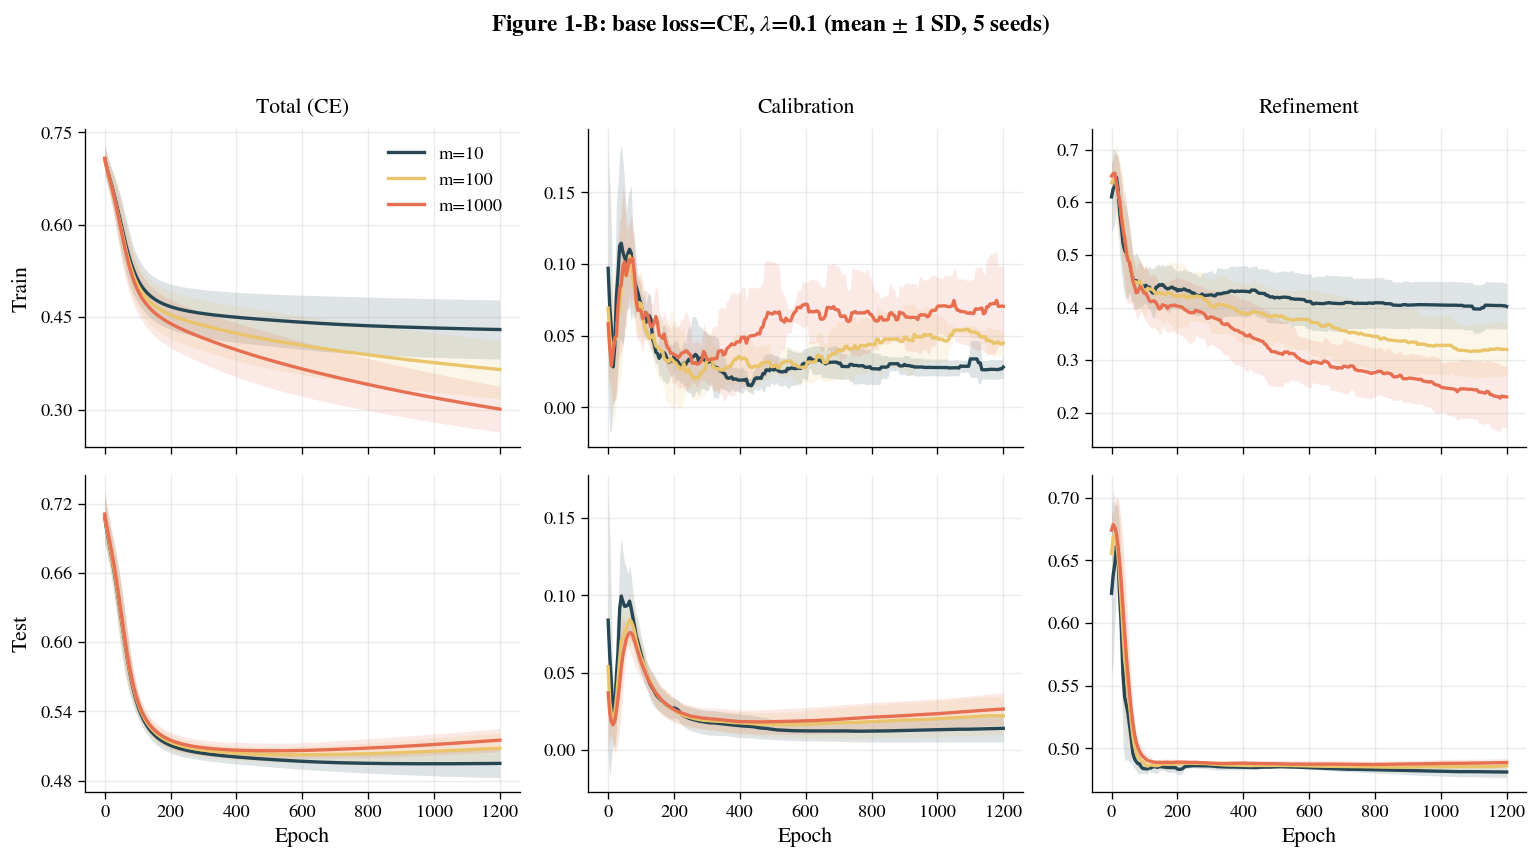

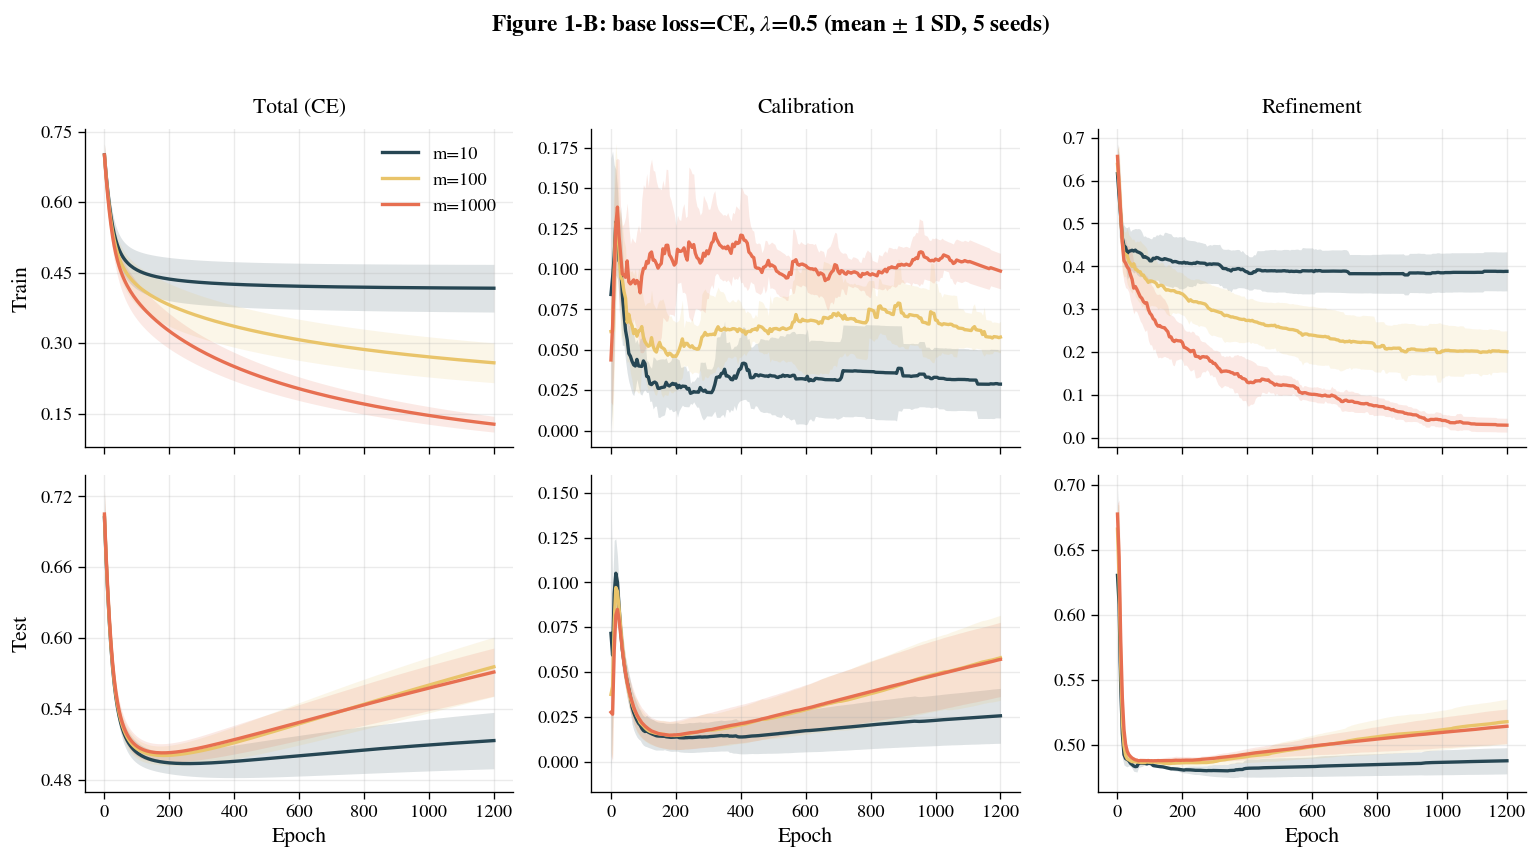

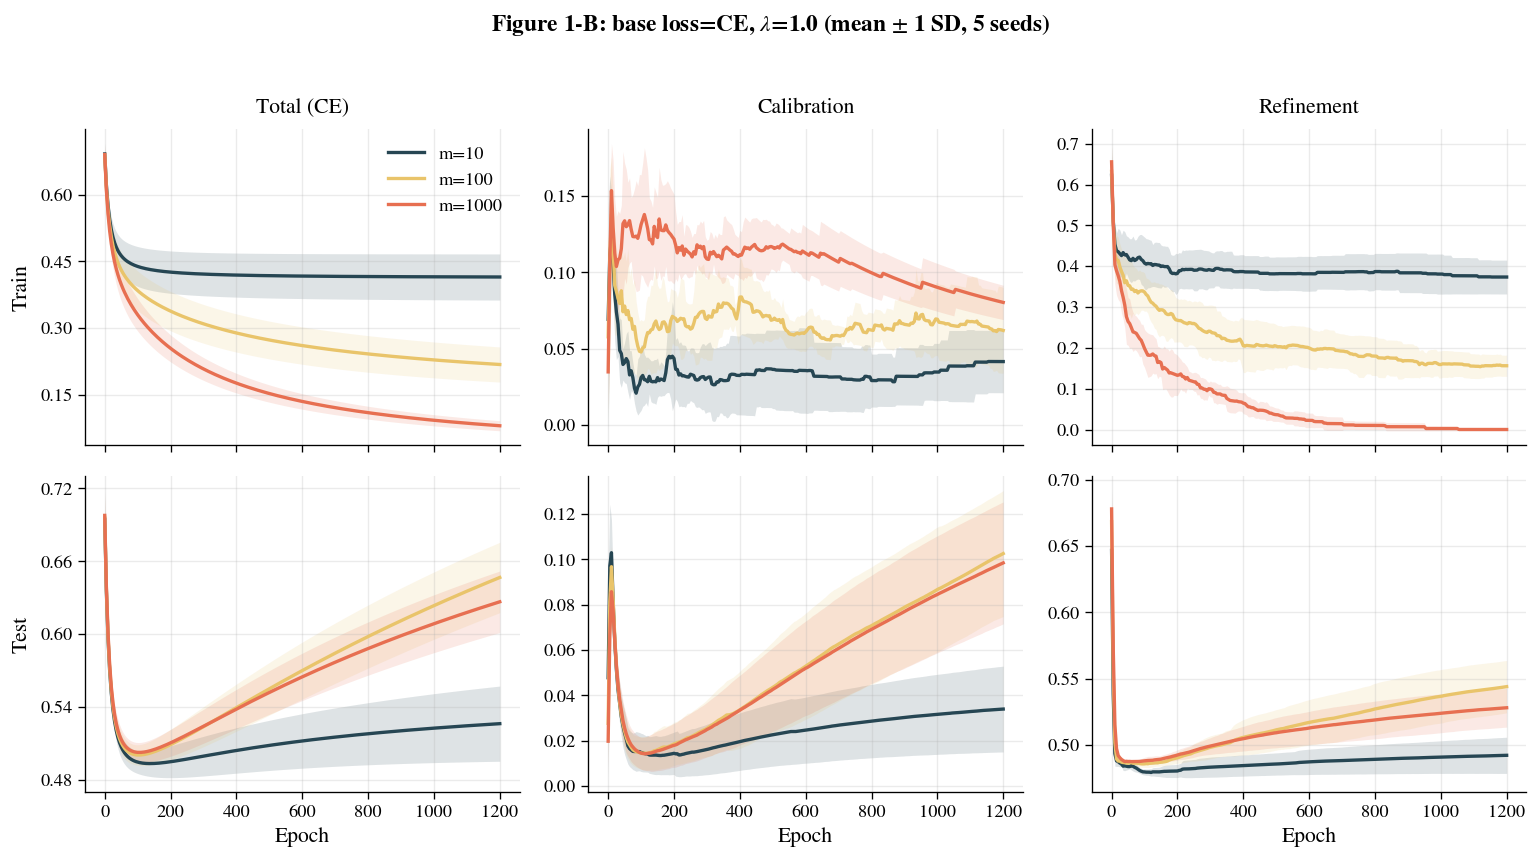

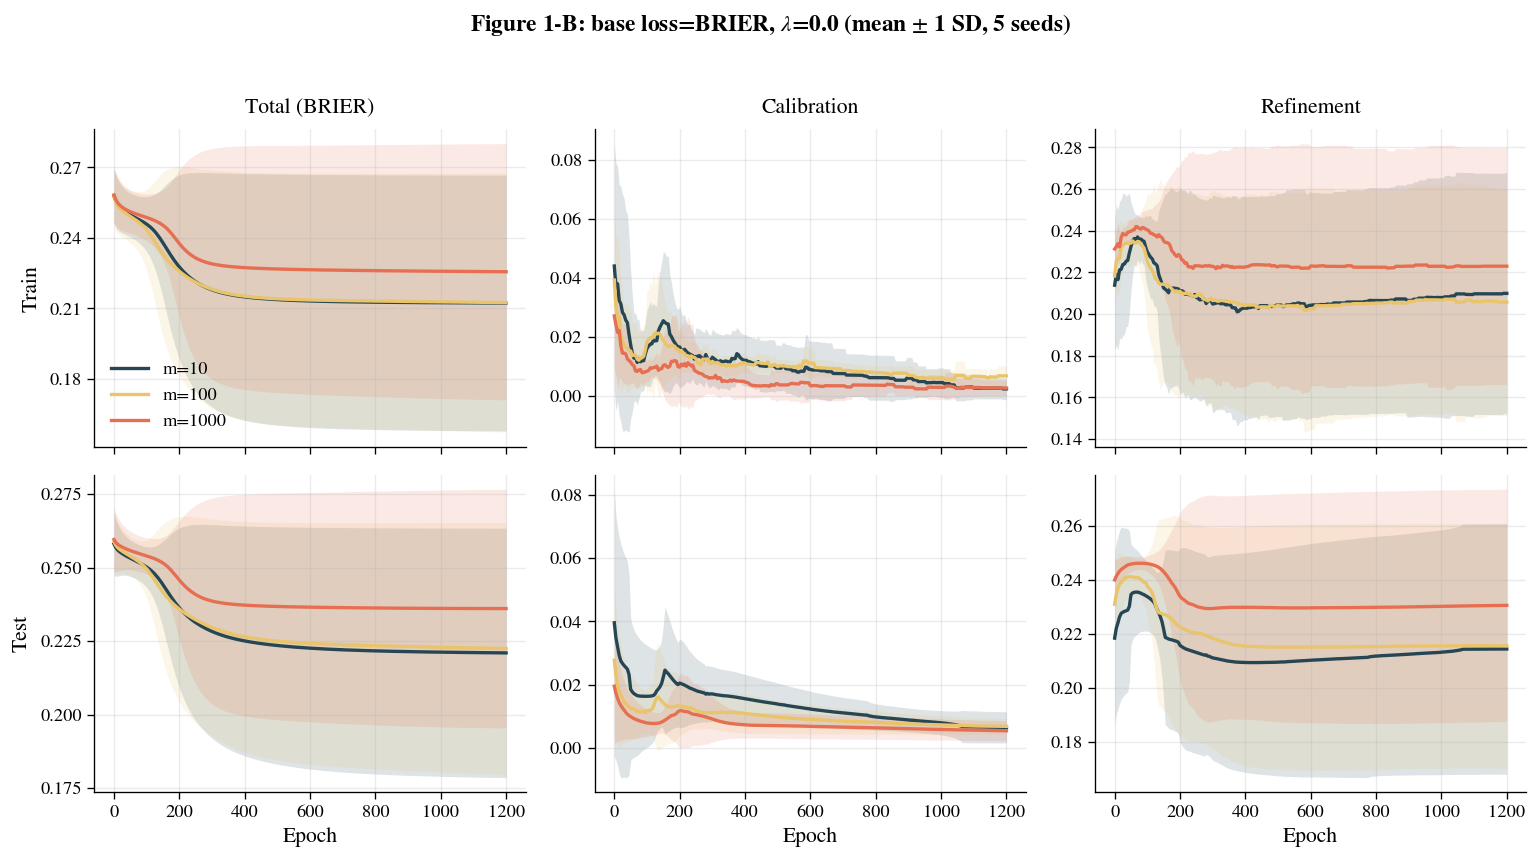

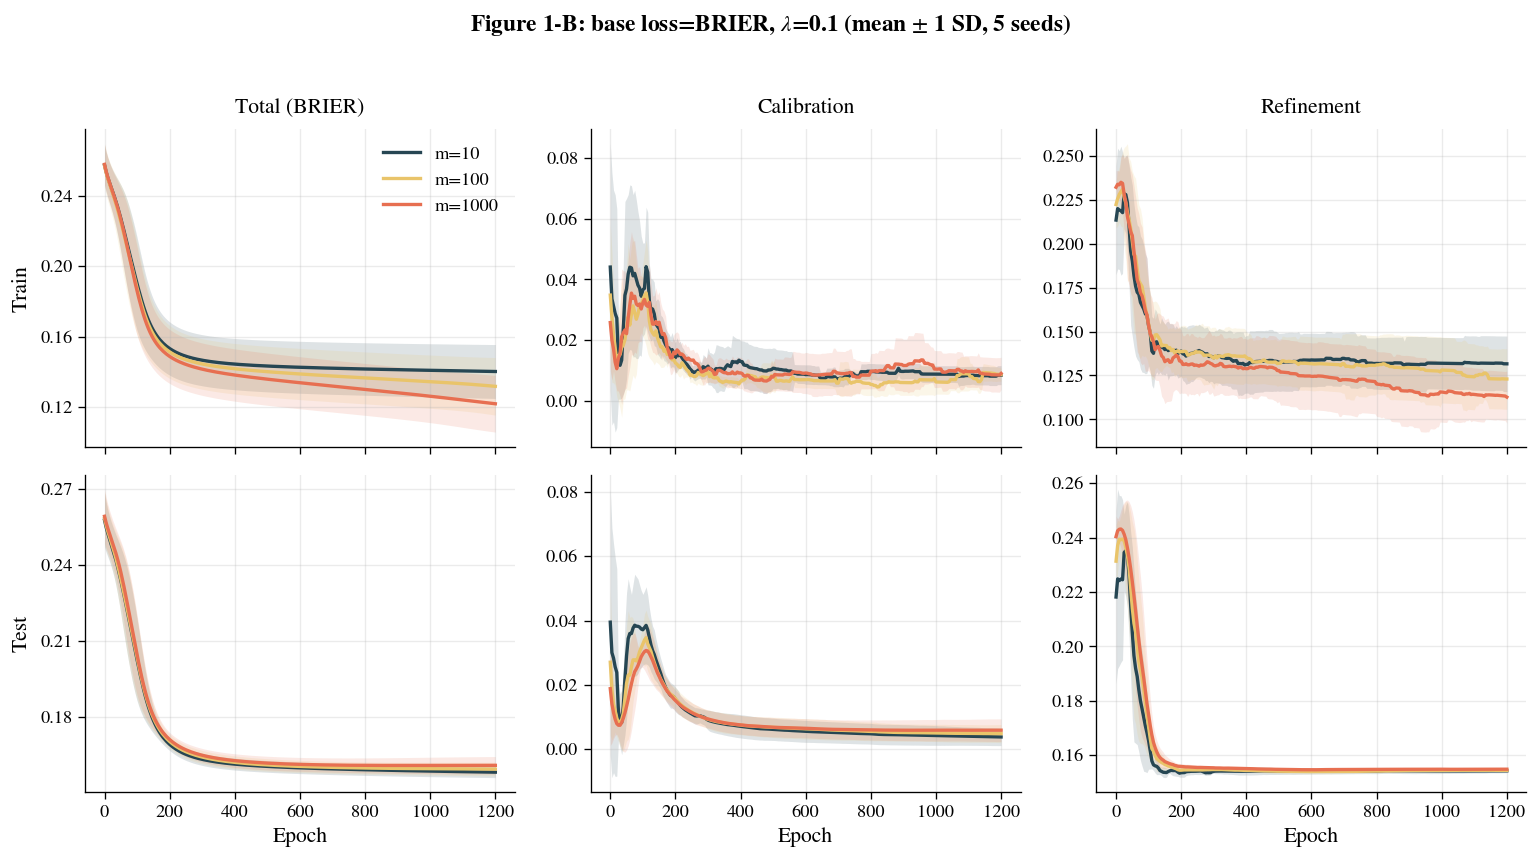

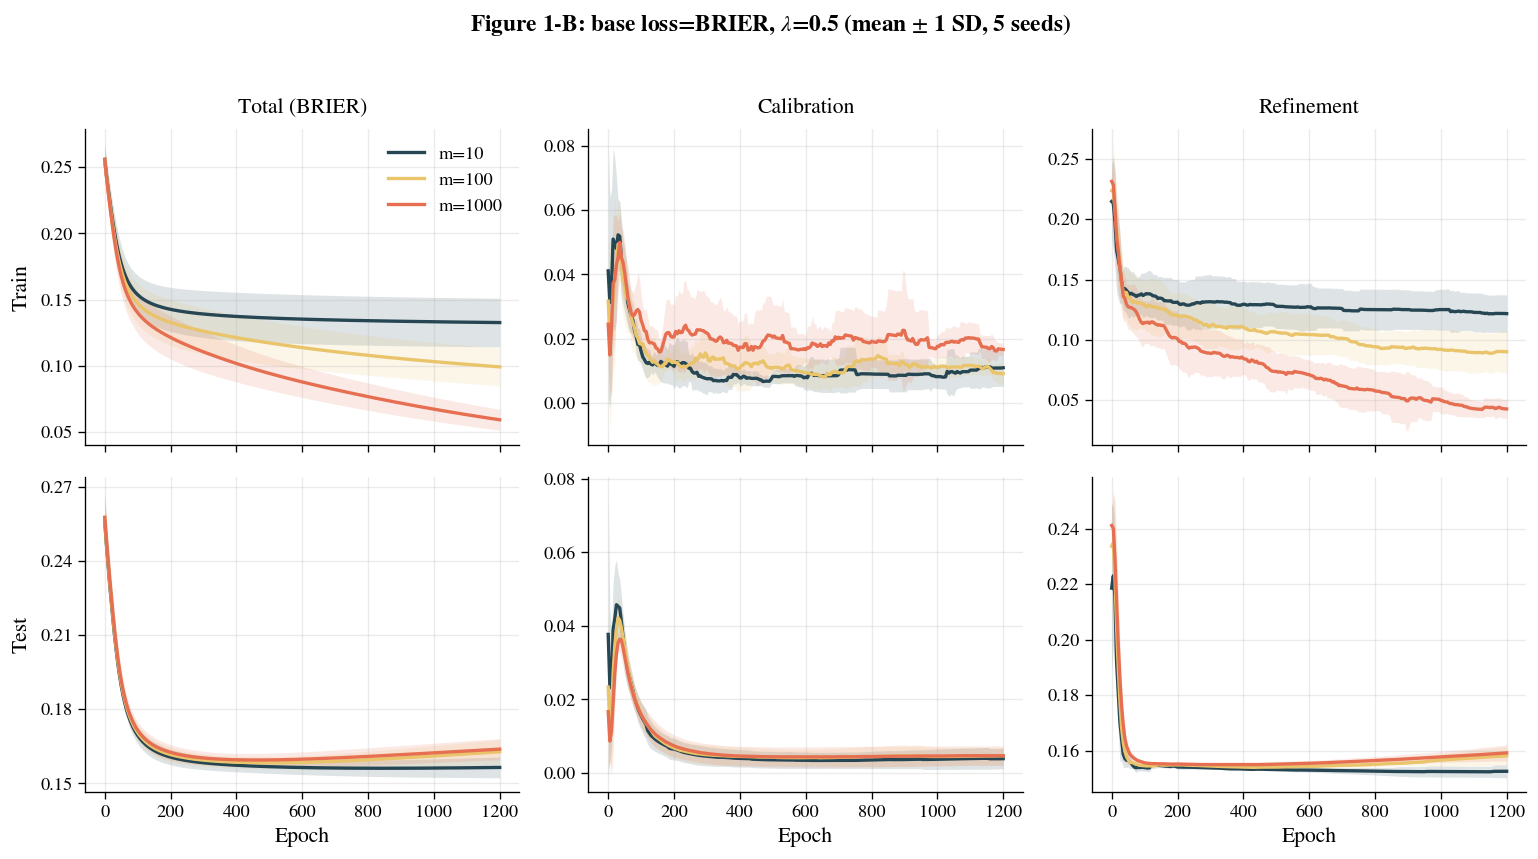

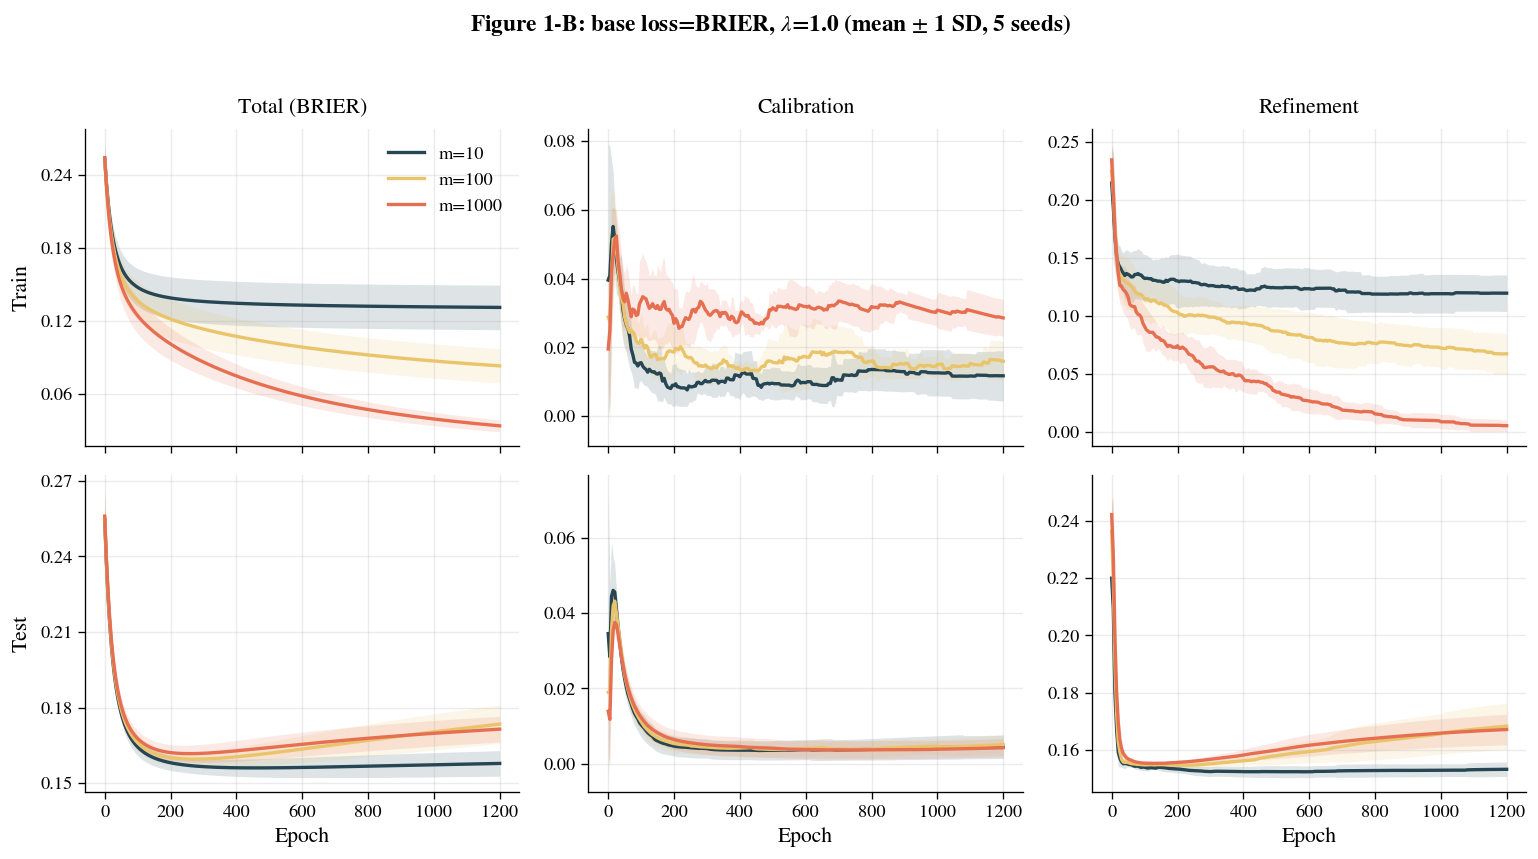

In [19]:
for base_loss in BASE_LOSSES:
    for lam in LAMBDA_GRID:
        fig = plot_figure_1b(all_results[(lam, base_loss)], lam=lam, base_loss=base_loss)
        plt.show()

In [20]:
import pandas as pd

rows = []

print("Test-set decomposition, epoch 0 -> epoch 1200 (mean ± sample SD across 5 seeds):\n")

for base_loss in BASE_LOSSES:
    for lam in LAMBDA_GRID:
        print(f"--- base_loss={base_loss.upper()}, lambda={lam} ---")
        for m in t1.PRIMARY_CAPACITIES:
            seed_logs = all_results[(lam, base_loss)][m]
            key_total, key_cal, key_ref = f"{base_loss}_total", f"{base_loss}_cal", f"{base_loss}_ref"

            values = {}
            for metric, key in [("total", key_total), ("cal", key_cal), ("ref", key_ref)]:
                start_values = [run["test"][0][key] for run in seed_logs]
                end_values = [run["test"][-1][key] for run in seed_logs]
                digits = 3 if metric == "total" else 4
                values[f"{metric}_epoch0"] = format_mean_sd(start_values, digits)
                values[f"{metric}_epoch1200"] = format_mean_sd(end_values, digits)

            # Store the reported values in X ± Y format for direct interpretation/export.
            rows.append({
                "base_loss": base_loss.upper(),
                "lambda": lam,
                "m": m,
                **values,
            })

            print(
                f"m={m:>4}:  total {values['total_epoch0']} -> {values['total_epoch1200']}   |   "
                f"cal {values['cal_epoch0']} -> {values['cal_epoch1200']}   |   "
                f"ref {values['ref_epoch0']} -> {values['ref_epoch1200']}"
            )
        print()

df_decomposition = pd.DataFrame(rows)
display(df_decomposition)

df_decomposition.to_csv("test_set_decomposition_5seeds.csv", index=False)
df_decomposition.to_excel("test_set_decomposition_5seeds.xlsx", index=False)

Test-set decomposition, epoch 0 -> epoch 1200 (mean ± sample SD across 5 seeds):

--- base_loss=CE, lambda=0.0 ---
m=  10:  total 0.709 ± 0.021 -> 0.633 ± 0.087   |   cal 0.0827 ± 0.0894 -> 0.0167 ± 0.0144   |   ref 0.6265 ± 0.0698 -> 0.6164 ± 0.1005
m= 100:  total 0.711 ± 0.021 -> 0.636 ± 0.088   |   cal 0.0567 ± 0.0480 -> 0.0171 ± 0.0108   |   ref 0.6541 ± 0.0289 -> 0.6191 ± 0.0982
m=1000:  total 0.712 ± 0.022 -> 0.665 ± 0.083   |   cal 0.0396 ± 0.0370 -> 0.0133 ± 0.0106   |   ref 0.6729 ± 0.0164 -> 0.6513 ± 0.0930

--- base_loss=CE, lambda=0.1 ---
m=  10:  total 0.708 ± 0.021 -> 0.495 ± 0.012   |   cal 0.0840 ± 0.0849 -> 0.0139 ± 0.0088   |   ref 0.6238 ± 0.0665 -> 0.4811 ± 0.0045
m= 100:  total 0.709 ± 0.021 -> 0.508 ± 0.013   |   cal 0.0537 ± 0.0447 -> 0.0220 ± 0.0122   |   ref 0.6556 ± 0.0262 -> 0.4861 ± 0.0026
m=1000:  total 0.711 ± 0.021 -> 0.515 ± 0.010   |   cal 0.0369 ± 0.0346 -> 0.0264 ± 0.0103   |   ref 0.6741 ± 0.0145 -> 0.4887 ± 0.0032

--- base_loss=CE, lambda=0.5 ---
m

,base_loss,lambda,m,total_epoch0,total_epoch1200,cal_epoch0,cal_epoch1200,ref_epoch0,ref_epoch1200
0,CE,0.0,10,0.709 ± 0.021,0.633 ± 0.087,0.0827 ± 0.0894,0.0167 ± 0.0144,0.6265 ± 0.0698,0.6164 ± 0.1005
1,CE,0.0,100,0.711 ± 0.021,0.636 ± 0.088,0.0567 ± 0.0480,0.0171 ± 0.0108,0.6541 ± 0.0289,0.6191 ± 0.0982
2,CE,0.0,1000,0.712 ± 0.022,0.665 ± 0.083,0.0396 ± 0.0370,0.0133 ± 0.0106,0.6729 ± 0.0164,0.6513 ± 0.0930
3,CE,0.1,10,0.708 ± 0.021,0.495 ± 0.012,0.0840 ± 0.0849,0.0139 ± 0.0088,0.6238 ± 0.0665,0.4811 ± 0.0045
4,CE,0.1,100,0.709 ± 0.021,0.508 ± 0.013,0.0537 ± 0.0447,0.0220 ± 0.0122,0.6556 ± 0.0262,0.4861 ± 0.0026
5,CE,0.1,1000,0.711 ± 0.021,0.515 ± 0.010,0.0369 ± 0.0346,0.0264 ± 0.0103,0.6741 ± 0.0145,0.4887 ± 0.0032
6,CE,0.5,10,0.702 ± 0.021,0.513 ± 0.024,0.0715 ± 0.0805,0.0255 ± 0.0153,0.6303 ± 0.0663,0.4876 ± 0.0101
7,CE,0.5,100,0.703 ± 0.021,0.576 ± 0.025,0.0374 ± 0.0317,0.0580 ± 0.0237,0.6659 ± 0.0190,0.5177 ± 0.0172
8,CE,0.5,1000,0.705 ± 0.021,0.571 ± 0.020,0.0275 ± 0.0243,0.0570 ± 0.0207,0.6775 ± 0.0083,0.5141 ± 0.0134
9,CE,1.0,10,0.695 ± 0.020,0.526 ± 0.031,0.0478 ± 0.0441,0.0340 ± 0.0189,0.6467 ± 0.0410,0.4924 ± 0.0136
